In this lesson, we will introduce a library that handles data in a more organized form, namely Pandas.

Pandas is a library in Python for handling data described in tabular form. As this is an introduction to this library, we will just give a brief introduction here.

First of all, installing Pandas is needed if this is the first time encountering this library.

In [7]:
!pip install Pandas

Then we need to import the library into this script.

In [9]:
import pandas as pd
import numpy as np
import matplotlib as plt

In this chapter, we will learn about
- [DataFrame](#df)
- [Importing data](#data)
- [Importing data from libraries](#data_lib)
- [Data Cleaning](#clean)

- [Training Exercises](#exercise)

<a id = 'df'></a>
# DataFrame

We call a table of data a DataFrame.

The rows are called 'index' and columns are simply referred to as 'columns'.

We need to define three objects before defining a DataFrame.
- Values
- Index
- Columns

In [14]:
#Example
df = pd.DataFrame(np.arange(16).reshape(4,4), index = [1,2,3,4], columns = ['a','b','c','d'])

In [15]:
df

,a,b,c,d
1,0,1,2,3
2,4,5,6,7
3,8,9,10,11
4,12,13,14,15


Recall in L1, we taught about a type of variable: Dictionary.

A dictionary stores data under specific keys set by users.

As dictionary shares a similar data structure with DataFrame, we can also define a DataFrame from a dictionary where keys will be turned into columns.

In [17]:
#Example
data = {'Price':[90,20,18,70], 'Age':[2,7,14,4],'Size':[10,15.5,6.75,8],'Height':[10, 12, 14, 15]}

df = pd.DataFrame(data)

In [18]:
df

,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


If we want to read a column from a DataFrame, we can use either of the following two:

In [20]:
df['Price']

0    90
1    20
2    18
3    70
Name: Price, dtype: int64

In [21]:
df.Price

0    90
1    20
2    18
3    70
Name: Price, dtype: int64

If we ant to read a specific row, we specify the location by the row index.

In [23]:
df.loc[1]

Price     20.0
Age        7.0
Size      15.5
Height    12.0
Name: 1, dtype: float64

By using 'describe' function, we can get a statistical summary of the DataFrame.

In [25]:
df.describe()

,Price,Age,Size,Height
count,4.000000,4.000000,4.000000,4.000000
mean,49.500000,6.750000,10.062500,12.750000
std,36.161674,5.251984,3.864232,2.217356
min,18.000000,2.000000,6.750000,10.000000
25%,19.500000,3.500000,7.687500,11.500000
50%,45.000000,5.500000,9.000000,13.000000
75%,75.000000,8.750000,11.375000,14.250000
max,90.000000,14.000000,15.500000,15.000000


Sometimes we would only like to see the first few rows of DataFrame, therefore using 'head' function give the first five rows of the DataFrame

In [27]:
df.head()

,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


DataFrame is a flexible regarding the naming convention.

Also, we can specify which columns in a dataset to be included in the DataFrame

We can also switch the ordering of the columns in the DataFrame.

In [29]:
df2 = pd.DataFrame(data, columns = ['Age','Size'], index = [1,2,3,4])

In [30]:
df2

,Age,Size
1,2,10.00
2,7,15.50
3,14,6.75
4,4,8.00


Visualizing data is one of most important steps in data analysis.

'plot()' generates graph with lines corresponding to the columns in DataFrame.

<Axes: >

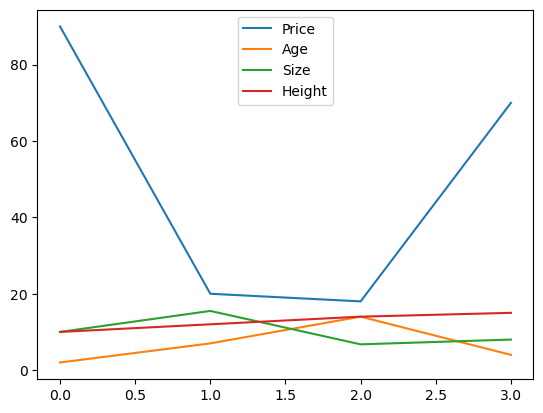

In [32]:
df.plot()

<Axes: >

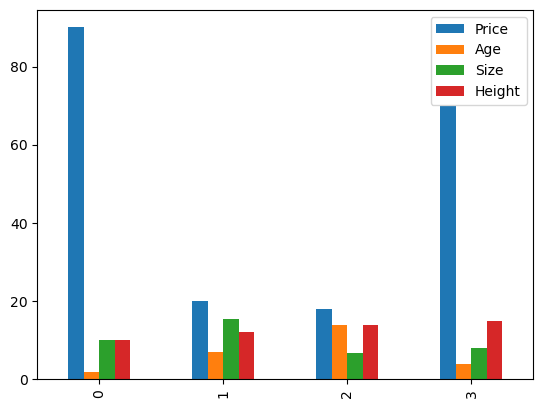

In [33]:
df.plot.bar()

<a id = 'data'></a>
# Importing data

In real life situations, data can be givin in a certain files of standard formats, such as excel or csv (comma separated values).

These files can be imported into Python through the 'read' function in pandas.

In [36]:
df = pd.read_csv('filename.csv', sep = ';')

df = pd.read_csv('filename.csv', sep = '\t')

#The two functions have the same structure, but different in the last argument.

#You should try with your own csv

FileNotFoundError: [Errno 2] No such file or directory: 'filename.csv'

'sep' or 'delimiter' are the regular expression for data separation indication, including ';'(semicolon), ','(comma), '\t'(tab)

<a id = 'data_lib'></a>
# Importing data from libraries

There are existing libraries that are really useful in learning machine learning related knowledge: scikit-learn.

This library provides datasets for users to test their codes. Therefore, I will demonstrate by using some of them.

In [41]:
from sklearn.datasets import load_wine
wine_dataset = load_wine()

To understand the components in the data set, we should check the keys in it. 

In [45]:
wine_dataset.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

- 'DESCR' gives the description of the dataset
- 'target_names' gives the names of the type
- 'target' stores the target values (label the type in terms of 0,1,2) of all given data
- 'feature_names' give the descriptions of the features ('alcohol',
 'malic_acid'
 'ash,
 'alcalinity_of_as ,
 'magnesim',
 'total_phenls',
 'flavan ds',
 'nonflavanoid_phnols',
 'proanthocanins',
 'color_inensity'
 'hue',
 'od280/od315_of_dilued_wines',)
- 'data' contains the feature values for the samples
 'proline'

By section 1, we can create a DataFrame if we have a set of data:

In [60]:
wine_dataframe = pd.DataFrame(wine_dataset['data'], columns = wine_dataset.feature_names)

In [66]:
wine_dataframe.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


We can also look into other things as we have the keys to construct the DataFrame with.

And joining two DataFrame together is possible.

In [69]:
wine_species = pd.DataFrame(wine_dataset['target'], columns = ['Species'])

df_all = pd.DataFrame.join(wine_dataframe, wine_species)

<a id = 'cleaning'></a>
# Data Cleaning

In real life situations, we often face incomplete data. In pandas, they are represented by 'NaN'.

In [77]:
#To delete the data point with missing entry
df.dropna()

,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


Alternatively, in some situation we would like to keep these data point. We can fill an artificial value by using 'fillna'.

In [86]:
df.fillna(0)

,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


Or we can just fill them by taking reference to neighbouring data point

In [89]:
df.fillna(method='ffill') #f for forward
#or
df.fillna(method='bfill') #b for backward

C:\Users\felix\AppData\Local\Temp\ipykernel_33700\1774442325.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill') #f for forward
C:\Users\felix\AppData\Local\Temp\ipykernel_33700\1774442325.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='bfill') #b for backward


,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


In some cases, we have duplicates in our data,we can delete one of them by

In [92]:
df.drop_duplicates()

,Price,Age,Size,Height
0,90,2,10.00,10
1,20,7,15.50,12
2,18,14,6.75,14
3,70,4,8.00,15


<a id = 'exercise'></a>
# Training Exercises

## Exercise 1

Import the Iris dataset from the scikit-learn module into a DataFrame named iris_dataframe. The dataset contains measurements of iris flowers, including sepal length, sepal width, petal length, petal width, and species.

Then show the first five lines of the dataframe

In [99]:
#Write your code here


## Exercise 2

Perform the following analyses on the iris_data DataFrame:

Check for any missing values in the DataFrame.
Get a summary of the dataset using the describe() method.

In [107]:
#Write your code here


## Exercise 3

Assume that some entries in the iris_data DataFrame have missing values. Perform the following:

If there are any missing values, fill them with the mean of the respective column.
Drop any rows where the species column is missing.

In [113]:
#Write your code here


## Exercise 4

Perform the following analyses on the iris_data DataFrame:

Calculate the average sepal length and petal width of the flowers.
Find the species with the maximum petal length and display their details.
Create a new column named sepal_area calculated as: sepal_area = sepal length * sepal width

Display the first 5 rows of the updated DataFrame.

In [126]:
#Write your code here


## Exercise 5

Use the matplotlib library to create a scatter plot showing the relationship between sepal length and sepal width, colored by species.

In [130]:
#Write your code here
